# pandas vs Polars on Metropolitan Police crime data

12 months of Met street-crime data (Sep 2025 to Aug 2026) from data.police.uk. Each task is run in both libraries, timed several times, and the median is kept.

In [1]:
import glob, statistics, time, platform
from pathlib import Path
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

print('pandas', pd.__version__, '| polars', pl.__version__, '|', platform.processor())
RAW = sorted(glob.glob('../data/raw/*-metropolitan-street.csv'))
PROC = Path('../data/processed'); PROC.mkdir(parents=True, exist_ok=True)
print(len(RAW), 'files')

pandas 3.1.0 | polars 2.1.0 | AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD
12 files


## 1. Combine the monthly files and save a Parquet copy

In [2]:
combined = pl.concat([pl.read_csv(f, infer_schema_length=10000) for f in RAW], how='vertical_relaxed')
combined.write_csv(PROC / 'met_street.csv')
combined.write_parquet(PROC / 'met_street.parquet')
print(combined.shape)
combined.head()

(1121303, 12)


Crime ID,Month,Reported by,Falls within,Longitude,Latitude,Location,LSOA code,LSOA name,Crime type,Last outcome category,Context
str,str,str,str,f64,f64,str,str,str,str,str,str
"""ddfc736bd648a8be19fc2ee1d8d899…","""2025-09""","""Metropolitan Police Service""","""Metropolitan Police Service""",-0.65746,50.78727,"""On or near Kingsmead""","""E01031419""","""Arun 015C""","""Violence and sexual offences""","""Status update unavailable""",null
"""e9554ad8c933c22d8179544db9f207…","""2025-09""","""Metropolitan Police Service""","""Metropolitan Police Service""",-1.308951,53.133272,"""On or near Pennine Close""","""E01027986""","""Ashfield 003B""","""Vehicle crime""","""Investigation complete; no sus…",null
"""33e23dc589145e543b9f1bf15b4a30…","""2025-09""","""Metropolitan Police Service""","""Metropolitan Police Service""",1.042429,52.005298,"""On or near Aisthorpe""","""E01029903""","""Babergh 010E""","""Violence and sexual offences""","""Status update unavailable""",null
null,"""2025-09""","""Metropolitan Police Service""","""Metropolitan Police Service""",0.140194,51.582356,"""On or near Hatch Grove""","""E01000027""","""Barking and Dagenham 001A""","""Anti-social behaviour""",null,null
null,"""2025-09""","""Metropolitan Police Service""","""Metropolitan Police Service""",0.142112,51.589389,"""On or near A1112""","""E01000027""","""Barking and Dagenham 001A""","""Anti-social behaviour""",null,null


## 2. A small lookup table for the join
Groups each crime type into a broader category. Check the crime types printed below and adjust if needed.

In [3]:
print(sorted(combined['Crime type'].unique().to_list()))
CATEGORY = {
    'Violence and sexual offences': 'Violent', 'Robbery': 'Violent', 'Possession of weapons': 'Violent',
    'Burglary': 'Property', 'Vehicle crime': 'Property', 'Theft from the person': 'Property',
    'Bicycle theft': 'Property', 'Shoplifting': 'Property', 'Other theft': 'Property',
    'Criminal damage and arson': 'Property',
    'Anti-social behaviour': 'Public order', 'Public order': 'Public order',
    'Drugs': 'Other', 'Other crime': 'Other',
}
lookup_pd = pd.DataFrame({'Crime type': list(CATEGORY), 'Category': list(CATEGORY.values())})
lookup_pl = pl.from_pandas(lookup_pd)

['Anti-social behaviour', 'Bicycle theft', 'Burglary', 'Criminal damage and arson', 'Drugs', 'Other crime', 'Other theft', 'Possession of weapons', 'Public order', 'Robbery', 'Shoplifting', 'Theft from the person', 'Vehicle crime', 'Violence and sexual offences']


## 3. The same pipeline in both libraries
Clean (drop empty columns, parse month, get borough from the LSOA name), group, and join.

In [4]:
CSV, PQ = PROC / 'met_street.csv', PROC / 'met_street.parquet'

def pd_load_csv(): return pd.read_csv(CSV)
def pd_load_parquet(): return pd.read_parquet(PQ)
def pd_clean(df):
    df = df.drop(columns=['Context'], errors='ignore').dropna(subset=['Crime type'])
    df['Month'] = pd.to_datetime(df['Month'], format='%Y-%m')
    df['Borough'] = df['LSOA name'].str.rsplit(' ', n=1).str[0]
    return df
def pd_group(df): return df.groupby(['Borough', 'Crime type']).size().reset_index(name='n')
def pd_join(df): return df.merge(lookup_pd, on='Crime type', how='left')
def pd_full(): return pd_group(pd_join(pd_clean(pd_load_parquet())))

def pl_load_csv(): return pl.read_csv(CSV, infer_schema_length=10000)
def pl_load_parquet(): return pl.read_parquet(PQ)
def pl_clean_expr(lf):
    return (lf.drop('Context', strict=False).drop_nulls('Crime type')
              .with_columns(pl.col('Month').str.strptime(pl.Date, '%Y-%m'),
                            pl.col('LSOA name').str.replace(r' \S+$', '').alias('Borough')))
def pl_clean(df): return pl_clean_expr(df.lazy()).collect()
def pl_group(df): return df.group_by(['Borough', 'Crime type']).len('n')
def pl_join(df): return df.join(lookup_pl, on='Crime type', how='left')
def pl_full(): return pl_group(pl_join(pl_clean(pl_load_parquet())))
def pl_full_lazy():
    return (pl_clean_expr(pl.scan_parquet(PQ)).join(lookup_pl.lazy(), on='Crime type', how='left')
              .group_by(['Borough', 'Crime type']).len('n').collect())

## 4. Time it

In [5]:
def timeit(fn, repeats=5):
    times = []
    for _ in range(repeats):
        t = time.perf_counter(); fn(); times.append(time.perf_counter() - t)
    return statistics.median(times)

pdf, pldf = pd_clean(pd_load_parquet()), pl_clean(pl_load_parquet())
tasks = {
    'Load CSV': (pd_load_csv, pl_load_csv),
    'Load Parquet': (pd_load_parquet, pl_load_parquet),
    'Clean': (lambda: pd_clean(pd_load_parquet()), lambda: pl_clean(pl_load_parquet())),
    'Group': (lambda: pd_group(pdf), lambda: pl_group(pldf)),
    'Join': (lambda: pd_join(pdf), lambda: pl_join(pldf)),
    'Full pipeline': (pd_full, pl_full),
}
rows = []
for name, (fpd, fpl) in tasks.items():
    rows.append({'task': name, 'pandas_s': timeit(fpd), 'polars_s': timeit(fpl)})
    print(rows[-1])
rows.append({'task': 'Full pipeline (Polars lazy)', 'pandas_s': None, 'polars_s': timeit(pl_full_lazy)})
results = pd.DataFrame(rows)
results['speedup'] = results['pandas_s'] / results['polars_s']
Path('../results').mkdir(exist_ok=True)
results.to_csv('../results/timings.csv', index=False)
results

{'task': 'Load CSV', 'pandas_s': 0.16141470009461045, 'polars_s': 0.1442044998984784}


{'task': 'Load Parquet', 'pandas_s': 0.09590869979001582, 'polars_s': 0.04862200003117323}


{'task': 'Clean', 'pandas_s': 1.2630113998893648, 'polars_s': 0.06825500004924834}


{'task': 'Group', 'pandas_s': 0.1256713999900967, 'polars_s': 0.04534429986961186}


{'task': 'Join', 'pandas_s': 0.12698710011318326, 'polars_s': 0.009986399905756116}


{'task': 'Full pipeline', 'pandas_s': 1.5658219999168068, 'polars_s': 0.11034220014698803}


,task,pandas_s,polars_s,speedup
0,Load CSV,0.161415,0.144204,1.119346
1,Load Parquet,0.095909,0.048622,1.972537
2,Clean,1.263011,0.068255,18.504306
3,Group,0.125671,0.045344,2.771493
4,Join,0.126987,0.009986,12.716004
5,Full pipeline,1.565822,0.110342,14.190600
6,Full pipeline (Polars lazy),NaN,0.034440,NaN


## 5. Charts

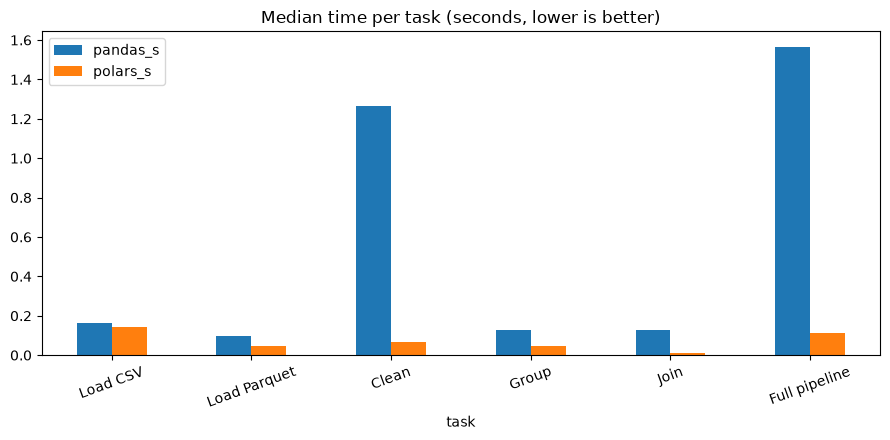

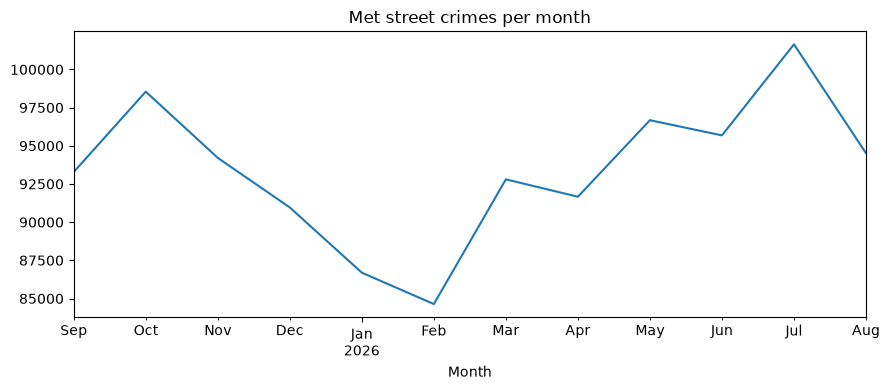

In [6]:
Path('../charts').mkdir(exist_ok=True)
r = results.dropna(subset=['pandas_s']).set_index('task')[['pandas_s', 'polars_s']]
ax = r.plot.bar(figsize=(9, 4.5), rot=20, title='Median time per task (seconds, lower is better)')
plt.tight_layout(); plt.savefig('../charts/timings.png', dpi=150); plt.show()

monthly = pldf.group_by('Month').len('n').sort('Month').to_pandas()
monthly.plot(x='Month', y='n', figsize=(9, 4), legend=False, title='Met street crimes per month')
plt.tight_layout(); plt.savefig('../charts/monthly_crime.png', dpi=150); plt.show()

## 6. Notes for the write-up
- Machine and versions (printed at the top)
- Which library was faster at each task, and by how much
- Which code felt easier to write
- Limits: one machine, one dataset, medians of a few runs